# 04 · E1: T5Gemma 9B-2B, zero-shot vs LoRA

End-to-end experiment for one backbone: data → zero-shot inference → LoRA fine-tuning → LoRA inference → evaluation on dev
(200 videos) and the held-out test set (1,448 videos, run once with the frozen configuration in `configs/frozen_test.json`).

In [1]:
%matplotlib inline
import json, statistics
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
import pandas as pd
from nbcommon import *

pd.set_option("display.max_colwidth", 80)
RUN_GPU = False   # True only on the training/inference machine (needs the models and a GPU)
print("project:", ROOT.name, "| run outputs read from:", A.relative_to(ROOT))

project: FinalProject | run outputs read from: artifacts


## 0. Configuration

In [2]:
ALIAS = "E1"
spec = BACKBONES[ALIAS]
frozen = load_json(ROOT / "configs/frozen_test.json")
display(pd.Series({"model": spec["model_id"], "revision": spec["revision"], "family": spec["family"],
                   "inference engine": "HF batched greedy" if spec["engine"] == "seq2seq" else "vLLM, native thinking",
                   "LoRA adapter": rel(spec["train_dir"] / "adapter")}))
print("frozen entries for this backbone:", [c for c in frozen["configurations"] if ALIAS in c] if isinstance(frozen.get("configurations"), dict) else "see configs/frozen_test.json")

model                              google/t5gemma-9b-2b-ul2-it
revision              99b9b9da34b8e66e2290c5c6d17306231c5b2566
family                                         encoder-decoder
inference engine                             HF batched greedy
LoRA adapter        artifacts/stage5-v1/E1-native-safe/adapter
dtype: str

frozen entries for this backbone: ['E1-ZS', 'E1-FT']


## 1. Data

All runs use the same window packs (notebook 02):
* **Training:** 1,000 training videos (1,306 windows), used for LoRA only.
* **Dev:** 200 validation videos (270 windows), used to select settings before the freeze.
* **Test:** 1,448 test videos (1,905 windows), run once.

In [3]:
dev_records, test_records = load_jsonl(DEV_RECORDS), load_jsonl(TEST_RECORDS)
print("dev:", len(dev_records), "videos,", sum(1 for _ in open(DEV_WINDOWS)), "windows")
print("test:", len(test_records), "videos,", sum(1 for _ in open(TEST_WINDOWS)), "windows")
print("train:", sum(1 for _ in open(TRAIN_WINDOWS)), "windows")

dev: 200 videos, 270 windows
test: 1448 videos, 1905 windows
train: 1306 windows


## 2. Zero-shot inference

The base model receives the window prompt, and its answer is parsed strictly. Inference settings are identical for zero-shot and LoRA.

Encoder-decoder models use **greedy decoding** in length tiers. Each window starts with a 384-token output cap; any window that hits the cap moves to the next tier (1,536, then 4,096 tokens).

In [4]:
for split in ["dev", "test"]:
    run(infer_command(ALIAS, split, "ZS"), RUN_GPU)

[not run here; RUN_GPU=False]  $ python scripts/infer_seq2seq_batched.py --alias E1 --windows artifacts/windows/dev-v2/validation_windows.jsonl --output artifacts/stage5-v1/E1-dev-ZS --square-budget 536870912
[not run here; RUN_GPU=False]  $ python scripts/infer_seq2seq_batched.py --alias E1 --windows artifacts/windows/test-v1/test_windows.jsonl --output artifacts/heldout-test-v1/E1-ZS-gpu2 --square-budget 536870912


In [5]:
def summary(split, arm):
    d = spec["runs"][(split, arm)]
    return load_json(d / "summary.json")

rows = []
for split in ["dev", "test"]:
    for arm in ["ZS", "FT"]:
        s = summary(split, arm)
        rows.append({"split": split, "arm": arm, "videos": s["requested_videos"], "windows": s["requested_windows"],
                     **{f"videos {k}": v for k, v in sorted(s["status_counts"].items())},
                     "generation min": round(s["generation_seconds"] / 60, 1), "output tokens": s["completion_tokens"]})
display(pd.DataFrame(rows).fillna(0).set_index(["split", "arm"]))

videos  windows  videos invalid  videos truncated  generation min  \
split arm                                                                      
dev   ZS      200      270             184              16.0            50.4   
      FT      200      270               2               0.0             6.2   
test  ZS     1448     1905            1306             129.0           339.2   
      FT     1448     1905              27               0.0            62.3   

           output tokens  videos ok  
split arm                            
dev   ZS          212624        0.0  
      FT           27798      198.0  
test  ZS         1578478       13.0  
      FT          198479     1421.0

In [6]:
# One raw zero-shot answer for a test window. Encoder-decoder output is the JSON itself.
raw = load_jsonl(spec["runs"][("test", "ZS")] / "windows.jsonl")
print("window statuses:", dict(Counter(r["status"] for r in raw)))
for wanted in ["ok", "failed"]:
    example = next((r for r in raw if (r["status"] == "ok") == (wanted == "ok")), None)
    if example is None:
        continue
    text = example.get("raw_text") or ""
    print(f"\n=== first {wanted} window: {example['video_id']} #{example['window_index']} | status {example['status']} | error {example.get('error')}")
    print("raw output:", len(text), "characters | reasoning tokens:", (example.get("usage") or {}).get("reasoning_tokens"))
    print(text[:600] + (" ..." if len(text) > 600 else ""))
    if example.get("final_text") and example["final_text"] != text:
        print("final answer:", example["final_text"][:400])

window statuses: {'invalid': 1684, 'ok': 15, 'truncated': 206}

=== first ok window: zUmEOjg0mYs #0 | status ok | error None
raw output: 1130 characters | reasoning tokens: 0
{
"chapters": [
{"start": 0, "title": "Introduction"},
{"start": 1, "title": "Background to the Conflict"},
{"start": 14, "title": "Background to the Conflict"},
{"start": 20, "title": "Origins of the Conflict"},
{"start": 25, "title": "Escalation of the Conflict"},
{"start": 30, "title": "The Military Operation"},
{"start": 35, "title": "Early Developments of the Conflict"},
{"start": 41, "title": "Government Claims Victory"},
{"start": 44, "title": "Uncertain Future of the Conflict"},
{"start": 46, "title": "Potential for Guerrilla Warfare"},
{"start": 52, "title": "Political Challenges"},
{ ...
final answer: {
"chapters": [
{"start": 0, "title": "Introduction"},
{"start": 1, "title": "Background to the Conflict"},
{"start": 14, "title": "Background to the Conflict"},
{"start": 20, "title": "Origins of the Confl

## 3. LoRA fine-tuning

* **Adapter:** LoRA rank 16, alpha 32, dropout 0.05, on q/k/v/o projections; the base model stays frozen (bf16).
* **Optimizer:** AdamW at 2e-4 with cosine decay and 10 warmup steps; gradient clipping 1.0.
* **Batching:** one window per forward pass, gradient accumulation 8, one pass over the 1,306 training windows.

The loss is decoder cross-entropy on the window's gold JSON. Titles that a window cannot support are masked out.

In [7]:
run(train_command(ALIAS), RUN_GPU)
report = load_json(spec["train_dir"] / "report.json")
keep = ["final_context", "rank", "lora_alpha", "lora_dropout", "target_modules", "learning_rate", "lr_schedule", "warmup_steps",
        "grad_accum", "actual_steps", "planned_optimizer_steps", "actual_training_videos", "trainable_parameters",
        "teacher_forcing_tokens", "first_loss", "last_loss", "mean_loss", "training_seconds", "peak_allocated_bytes",
        "optimizer_update_verified", "save_reload_adapter_tensors_equal"]
display(pd.Series({k: report.get(k) for k in keep}))

[not run here; RUN_GPU=False]  $ python scripts/train_lora.py --alias E1 --windows artifacts/windows/dev-v2/train_windows.jsonl --max-steps 0 --target-modules q_proj,k_proj,v_proj,o_proj --learning-rate 2e-4 --lr-schedule cosine --checkpoint-every 100 --grad-accum 8 --warmup-steps 10 --output artifacts/stage5-v1/E1-native-safe


final_context                                      native_template_v1
rank                                                               16
lora_alpha                                                         32
lora_dropout                                                     0.05
target_modules                       [q_proj, k_proj, v_proj, o_proj]
learning_rate                                                  0.0002
lr_schedule                                                    cosine
warmup_steps                                                       10
grad_accum                                                          8
actual_steps                                                     1306
planned_optimizer_steps                                           164
actual_training_videos                                           1000
trainable_parameters                                         31735808
teacher_forcing_tokens                                        5920923
first_loss          

{'adapter_model.safetensors': '121.2 MiB', 'README.md': '0.0 MiB', 'adapter_config.json': '0.0 MiB'}


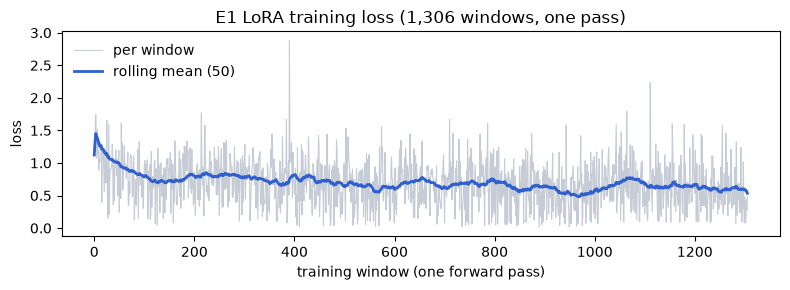

In [8]:
plot_loss(spec["train_dir"] / "steps.jsonl", "E1 LoRA training loss (1,306 windows, one pass)")
plt.tight_layout()
adapter = spec["train_dir"] / "adapter"
print({p.name: f"{p.stat().st_size / 2**20:.1f} MiB" for p in adapter.iterdir()} if adapter.exists() else "adapter not downloaded")

## 4. LoRA inference (same engine and settings, adapter loaded)

In [9]:
for split in ["dev", "test"]:
    if spec["engine"] == "seq2seq":
        run(infer_command(ALIAS, split, "FT"), RUN_GPU)
    else:
        print(f"{split}: the LoRA arm ran in the same vLLM call as zero-shot (--arms ZS FT), shown above")

[not run here; RUN_GPU=False]  $ python scripts/infer_seq2seq_batched.py --alias E1 --adapter artifacts/stage5-v1/E1-native-safe/adapter --windows artifacts/windows/dev-v2/validation_windows.jsonl --output artifacts/stage5-v1/E1-dev-FT --square-budget 536870912
[not run here; RUN_GPU=False]  $ python scripts/infer_seq2seq_batched.py --alias E1 --adapter artifacts/stage5-v1/E1-native-safe/adapter --windows artifacts/windows/test-v1/test_windows.jsonl --output artifacts/heldout-test-v1/E1-FT --square-budget 536870912


## 5. Evaluation

The saved predictions are re-scored with the project evaluator and checked against the saved evaluation files. The full metric set and the paired bootstrap come from `scripts/evaluate_predictions.py`.

In [10]:
recomputed, results = {}, []
for split, records in [("dev", DEV_RECORDS), ("test", TEST_RECORDS)]:
    for arm in ["ZS", "FT"]:
        recomputed[(split, arm)] = recompute(records, spec["runs"][(split, arm)] / "predictions.jsonl")
    saved_ft, saved_zs, saved_boot = paired_metrics(paired_file(ALIAS, split))
    assert abs(recomputed[(split, "FT")]["aggregate"]["macro_exact_f1"] - saved_ft["exact_f1"]) < 1e-12
    assert abs(recomputed[(split, "ZS")]["aggregate"]["macro_exact_f1"] - saved_zs["exact_f1"]) < 1e-12
    results += [(f"{split} zero-shot", saved_zs), (f"{split} LoRA", saved_ft)]
    print(f"{split}: LoRA − zero-shot exact F1 = {saved_boot['mean_difference']:+.3f} "
          f"[{saved_boot['confidence_interval'][0]:+.3f}, {saved_boot['confidence_interval'][1]:+.3f}] "
          f"(paired bootstrap, {saved_boot['videos']} videos)")
print("re-scored exact F1 matches the saved evaluation for all four runs")
display(metric_table(results))

dev: LoRA − zero-shot exact F1 = +0.508 [+0.466, +0.550] (paired bootstrap, 200 videos)


test: LoRA − zero-shot exact F1 = +0.481 [+0.465, +0.497] (paired bootstrap, 1448 videos)
re-scored exact F1 matches the saved evaluation for all four runs


,videos,failed,exact_f1,tolerant_f1,pk,window_diff,boundary_similarity,title_rouge_l,title_bertscore,pred_per_ref
configuration,,,,,,,,,,
dev zero-shot,200,200,0.000,0.000,1.000,1.000,0.000,0.000,0.000,0.000
dev LoRA,200,2,0.508,0.679,0.228,0.251,0.484,0.362,0.639,0.932
test zero-shot,1448,1435,0.003,0.004,0.995,0.997,0.002,0.002,0.002,0.017
test LoRA,1448,27,0.484,0.663,0.244,0.265,0.461,0.365,0.634,0.945


In [11]:
lenient = {arm: metrics(load_json(TEST / f"envelope-{ALIAS}-{arm}-metrics.json")) for arm in ["ZS", "FT"]}
print("Secondary lenient reading on test (one Markdown fence / trailing period stripped):")
display(metric_table([("test zero-shot (lenient)", lenient["ZS"]), ("test LoRA (lenient)", lenient["FT"])]))

Secondary lenient reading on test (one Markdown fence / trailing period stripped):


,videos,failed,exact_f1,tolerant_f1,pk,window_diff,boundary_similarity,title_rouge_l,title_bertscore,pred_per_ref
configuration,,,,,,,,,,
test zero-shot (lenient),1448,355,0.237,0.380,0.548,0.639,0.215,0.194,0.374,1.635
test LoRA (lenient),1448,27,0.484,0.663,0.244,0.265,0.461,0.365,0.634,0.945


## 6. One test video: gold vs zero-shot vs LoRA

In [12]:
zs_pred, ft_pred = by_id(spec["runs"][("test", "ZS")] / "predictions.jsonl"), by_id(spec["runs"][("test", "FT")] / "predictions.jsonl")
window_count = Counter(json.loads(line)["window"]["video_id"] for line in open(TEST_WINDOWS))
# first single-window test video of moderate length (display only; nothing is selected or tuned on test)
example = next(r for r in test_records if window_count[r["video_id"]] == 1 and 60 <= len(r["sentences"]) <= 120
               and 5 <= len(r["reference"]["chapter_starts"]) <= 9)
vid = example["video_id"]
print(vid, "|", len(example["sentences"]), "sentences | ZS status:", zs_pred[vid]["status"], "| LoRA status:", ft_pred[vid]["status"])
display(chapters_side_by_side(example, {"zero-shot": zs_pred[vid], "LoRA": ft_pred[vid]}))

_-x90wGBD8U | 119 sentences | ZS status: invalid | LoRA status: ok


,gold,zero-shot,LoRA
start sentence,,,
0,Introduction,,What is e?
7,Natural Log,,
14,Understanding Growth,,Growth
48,,,Continuous Growth
49,Growth Formula,,
98,What is e?,,What is e?
107,Value of e,,
110,,,Growth Rate and Time Periods


## 7. Error analysis

In [13]:
# Exact F1 on test by number of windows per video.
rows = []
for arm in ["ZS", "FT"]:
    buckets = defaultdict(list)
    for score in recomputed[("test", arm)]["per_video"]:
        buckets[min(window_count[score["video_id"]], 3)].append(score["exact"]["f1"])
    rows.append({"arm": arm, **{("3+ windows" if k == 3 else f"{k} window" + ("s" if k > 1 else "")): round(statistics.mean(v), 3)
                               for k, v in sorted(buckets.items())},
                 **{f"status {k}": v for k, v in recomputed[("test", arm)]["aggregate"]["status_counts"].items()}})
display(pd.DataFrame(rows).fillna(0).set_index("arm"))

,1 window,2 windows,3+ windows,status invalid,status truncated,status ok
arm,,,,,,
ZS,0.003,0.000,0.000,1306,129.0,13
FT,0.523,0.316,0.224,27,0.0,1421


In [14]:
# Where zero-shot fails: window-level statuses and the output tier reached.
for arm in ["ZS", "FT"]:
    s = load_json(spec["runs"][("test", arm)] / "summary.json")
    print(arm, "window statuses:", s.get("window_status_counts"), "| tiers:",
          [(t["cap"], t["windows"], t["carried_to_next"]) for t in s.get("tiers", [])])

ZS window statuses: {'invalid': 1684, 'truncated': 206, 'ok': 15} | tiers: [(384, 1905, 784), (1536, 784, 332), (4096, 332, 0)]
FT window statuses: {'ok': 1878, 'invalid': 27} | tiers: [(384, 1905, 8), (1536, 8, 1), (4096, 1, 0)]


## 8. Takeaway

Zero-shot E1 almost never produces the required JSON: on test, 13 of 1,448 videos are valid and 129 are cut off at the 4,096-token cap. Pilot-scale LoRA fixes the format and reaches exact F1 0.484 on test (+0.481). It is still slightly below the much smaller E2 (−0.017, post-hoc).